upload data g drive

In [ ]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')
print ("Google Drive berhasil terhubung")

file_path = '/content/drive/MyDrive/BIG DATA/dataset_final_with_sentimen (2).csv'

try:
  df = pd.read_csv(file_path, sep=';')
  print("dataset berhasil di baca")

  display(df.head())

except FileNotFoundError :
  print("file tidak ditemukan")

Mounted at /content/drive
Google Drive berhasil terhubung
dataset berhasil di baca


,Judul,Isi,Tanggal,Link,Sumber,Sentimen
0,"SBY Hadiri Halalbihalal di Istana, Disambut La...",sby hadiri halalbihalal di istana disambut lan...,"Kompas.com, 21 Maret 2026, 16:10 WIB",https://nasional.kompas.com/read/2026/03/21/16...,Kompas,Netral
1,"Suasana Hangat Halalbihalal di Istana, Warga h...",suasana hangat halalbihalal di istana warga hi...,"Kompas.com, 22 Maret 2026, 10:47 WIB",https://nasional.kompas.com/read/2026/03/22/10...,Kompas,Netral
2,KPK Alihkan Eks Menag Yaqut ke Tahanan Rumah S...,kpk alihkan eks menag yaqut ke tahanan rumah s...,"Kompas.com, 22 Maret 2026, 10:06 WIB",https://nasional.kompas.com/read/2026/03/22/10...,Kompas,Netral
3,"Momen Kebersamaan Prabowo, Titiek, dan Didit S...",momen kebersamaan prabowo titiek dan didit saa...,"Kompas.com, 22 Maret 2026, 09:17 WIB",https://nasional.kompas.com/read/2026/03/22/09...,Kompas,Netral
4,Momen Hangat Prabowo Sambut Jokowi di Istana: ...,momen hangat prabowo sambut jokowi di istana m...,"Kompas.com, 22 Maret 2026, 08:06 WIB",https://nasional.kompas.com/read/2026/03/22/08...,Kompas,Netral


struktur data

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67263 entries, 0 to 67262
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Judul     67263 non-null  object
 1   Isi       67263 non-null  object
 2   Tanggal   67261 non-null  object
 3   Link      67261 non-null  object
 4   Sumber    67261 non-null  object
 5   Sentimen  67259 non-null  object
dtypes: object(6)
memory usage: 3.1+ MB


jumlah data

In [ ]:
df.shape

(67263, 6)

cek missing value

In [ ]:
print(df.isnull().sum())

Judul       0
Isi         0
Tanggal     2
Link        2
Sumber      2
Sentimen    4
dtype: int64


In [ ]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:
    df[col].fillna(df[col].mean(), inplace=True)

# untuk kolom kategorikal -> isi dengan modus
categorical_columns = df.select_dtypes(include=['object']).columns

for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("=== Missing Value Setelah Ditangani ===")
print(df.isnull().sum())

# output_path = '/content/drive/MyDrive/BIG DATA/dataset_bersih.csv'

# df.to_csv(
#     output_path,
#     sep=';',
#     index=False,
#     encoding='utf-8'
# )

# print(f"Dataset bersih berhasil disimpan di: {output_path}")

/tmp/ipykernel_1031/3359201265.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


=== Missing Value Setelah Ditangani ===
Judul       0
Isi         0
Tanggal     0
Link        0
Sumber      0
Sentimen    0
dtype: int64
Dataset bersih berhasil disimpan di: /content/drive/MyDrive/BIG DATA/dataset_bersih.csv


distribusi sentimen

In [ ]:
df['Sentimen'].value_counts()

,count
Sentimen,
Netral,48991
Negatif,10876
Positif,7396


visualisasi sentimen

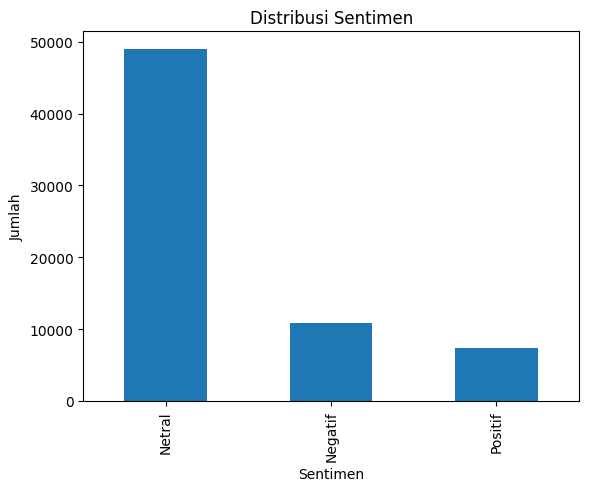

In [ ]:
import matplotlib.pyplot as plt

df['Sentimen'].value_counts().plot(kind='bar')
plt.title('Distribusi Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah')
plt.show()

Machine Learning

In [ ]:
df['text'] = df['Judul'].astype(str) + " " + df['Isi'].astype(str)

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')
X = tfidf.fit_transform(df['text'])

clustering

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans( n_clusters=3, random_state=42, n_init=10 )

kmeans.fit(X)
# Menambahkan hasil cluster ke dataframe
df['Topik_Cluster'] = kmeans.labels_

# Menampilkan hasil cluster
print(df[['Judul', 'Topik_Cluster']].head(100))


                                                Judul  Topik_Cluster
0   SBY Hadiri Halalbihalal di Istana, Disambut La...              2
1   Suasana Hangat Halalbihalal di Istana, Warga h...              0
2   KPK Alihkan Eks Menag Yaqut ke Tahanan Rumah S...              1
3   Momen Kebersamaan Prabowo, Titiek, dan Didit S...              0
4   Momen Hangat Prabowo Sambut Jokowi di Istana: ...              2
..                                                ...            ...
95  Viral Isu PHK Buruh Gudang Garam, Said Iqbal: ...              0
96         Gempa M 5,3 Guncang Pulau Doi Maluku Utara              0
97  Toko Emas Palsu di Riau Dibongkar Polisi, Perh...              1
98  Minyakita Tak Sesuai Ukuran juga Ditemukan di ...              1
99  Pimpin LDP, Sanae Takaichi Calon Kuat PM Perem...              2

[100 rows x 2 columns]


In [ ]:
# Memberi nama topik pada setiap cluster
topik_nama = {
    0: 'Politik',
    1: 'Kriminal',
    2: 'Nasional'
}

# Mengubah angka cluster menjadi nama topik
df['Topik'] = df['Topik_Cluster'].map(topik_nama)

# Menampilkan hasil akhir
print(df[['Judul', 'Topik']].head(100))

output_path = '/content/drive/MyDrive/BIG DATA/dataset_final_visualisasi.csv'

df.to_csv(
    output_path,
    sep=';',
    index=False,
    encoding='utf-8'
)

print("Dataset final berhasil disimpan")
print("Lokasi:", output_path)

                                                Judul     Topik
0   SBY Hadiri Halalbihalal di Istana, Disambut La...  Nasional
1   Suasana Hangat Halalbihalal di Istana, Warga h...   Politik
2   KPK Alihkan Eks Menag Yaqut ke Tahanan Rumah S...  Kriminal
3   Momen Kebersamaan Prabowo, Titiek, dan Didit S...   Politik
4   Momen Hangat Prabowo Sambut Jokowi di Istana: ...  Nasional
..                                                ...       ...
95  Viral Isu PHK Buruh Gudang Garam, Said Iqbal: ...   Politik
96         Gempa M 5,3 Guncang Pulau Doi Maluku Utara   Politik
97  Toko Emas Palsu di Riau Dibongkar Polisi, Perh...  Kriminal
98  Minyakita Tak Sesuai Ukuran juga Ditemukan di ...  Kriminal
99  Pimpin LDP, Sanae Takaichi Calon Kuat PM Perem...  Nasional

[100 rows x 2 columns]
Dataset final berhasil disimpan
Lokasi: /content/drive/MyDrive/BIG DATA/dataset_final_visualisasi.csv


distribusi cluster

In [ ]:
df['Topik_Cluster'].value_counts()

,count
Topik_Cluster,
0,44138
1,15440
2,7685


visualisasi cluster

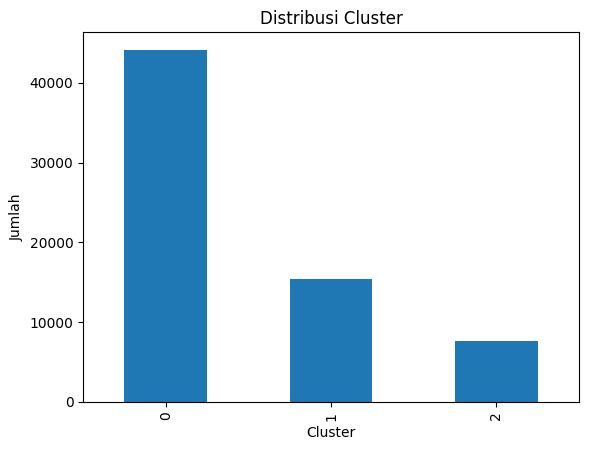

In [ ]:
import matplotlib.pyplot as plt

df['Topik_Cluster'].value_counts().plot(kind='bar')
plt.title('Distribusi Cluster')
plt.xlabel('Cluster')
plt.ylabel('Jumlah')
plt.show()

In [ ]:
print(df.count())

Judul            67263
Isi              67263
Tanggal          67263
Link             67263
Sumber           67263
Sentimen         67263
text             67263
Topik_Cluster    67263
Topik            67263
dtype: int64


visualisasi pie chart

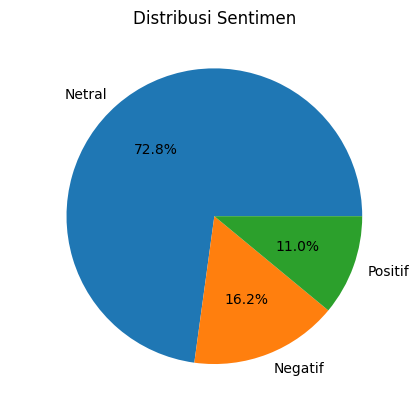

In [ ]:
import matplotlib.pyplot as plt

df['Sentimen'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribusi Sentimen')
plt.ylabel(" ")
plt.show()

sentimen vs cluster

In [ ]:
import pandas as pd

pd.crosstab(df['Topik_Cluster'], df['Sentimen'])

Sentimen,Negatif,Netral,Positif
Topik_Cluster,,,
0,7586,29962,6590
1,2388,13022,30
2,902,6007,776


visualisasi sentimen vs cluster

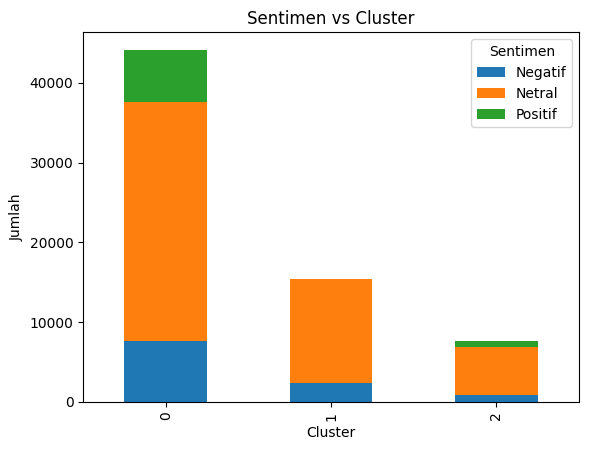

In [ ]:
import matplotlib.pyplot as plt

ct = pd.crosstab(df['Topik_Cluster'], df['Sentimen'])
ct.plot(kind ='bar', stacked = True)
plt.title('Sentimen vs Cluster')
plt.xlabel('Cluster')
plt.ylabel('Jumlah')
plt.show()